# Figure S1b: density overlap between the subtropical North Atlantic and the Southern Ocean channel, 8xCO2

As Figure 3, with the northern region changed to 30-40N.

Input: `FMAASOmean_sigma1_cells_8x_natl20-80N_so75-50S.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=14)

In [2]:
series = common.density_ranges('8x', common.STNA_LAT)

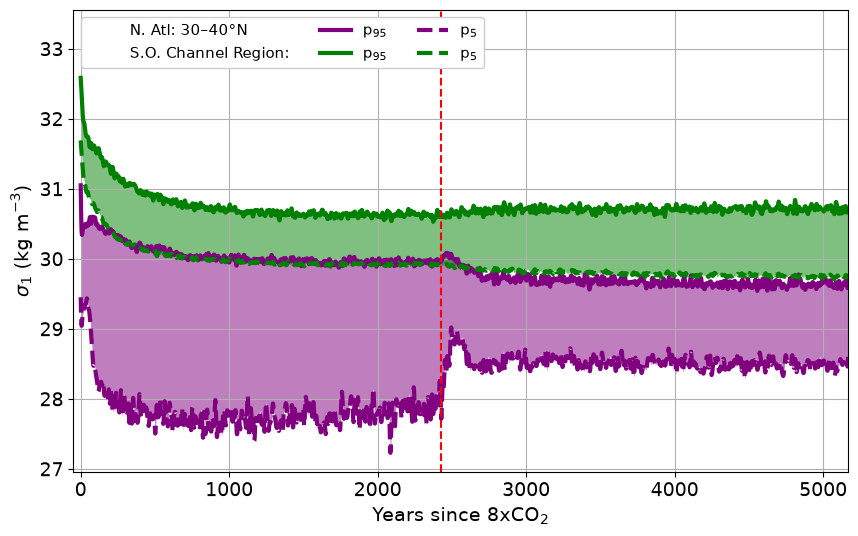

In [3]:
def plot_density_bands(ax, series, event_year=None, natl_header='N. Atl:', linewidth=2.5):
    """Draw a run's N. Atlantic and Southern Ocean density ranges on ax: p95 solid, p5 dashed, range shaded."""
    years = series['years']
    natl_color, so_color = 'purple', 'green'
    hi_label, lo_label = f'p$_{{{common.PCT_HI}}}$', f'p$_{{{common.PCT_LO}}}$'
    # Invisible handles act as the two row headers of the legend
    ax.plot([], [], linestyle='None', color='None', label=natl_header)
    ax.plot([], [], linestyle='None', color='None', label='S.O. Channel Region:')
    ax.plot(years, series['natl_hi'], color=natl_color, linewidth=linewidth, label=hi_label)
    ax.plot(years, series['so_hi'], color=so_color, linewidth=linewidth, label=hi_label)
    ax.plot(years, series['natl_lo'], color=natl_color, linestyle='--', linewidth=linewidth, label=lo_label)
    ax.plot(years, series['so_lo'], color=so_color, linestyle='--', linewidth=linewidth, label=lo_label)
    ax.fill_between(years, series['natl_hi'], series['natl_lo'], alpha=0.5, color=natl_color, linewidth=0)
    ax.fill_between(years, series['so_hi'], series['so_lo'], alpha=0.5, color=so_color, linewidth=0)
    if event_year is not None:
        ax.axvline(event_year, color='red', linestyle='--', linewidth=1.5)
    ax.grid()


lat0, lat1 = common.STNA_LAT
fig, ax = plt.subplots(figsize=(10, 6))
plot_density_bands(ax, series, common.RECOVERY_YEAR, natl_header=f'N. Atl: {lat0}–{lat1}°N', linewidth=3)
ax.set_xlim(series['years'][0] - common.X_START_PAD, series['years'][-1])
# Autoscaled y range, with room added above the data for the legend
y_low, y_high = ax.get_ylim()
ax.set_ylim(y_low, y_high + 0.12 * (y_high - y_low))
ax.legend(ncol=3, fontsize=11, loc='upper left').get_frame().set_alpha(1)
ax.set_ylabel('$\\sigma_1$ (kg m$^{-3}$)')
ax.set_xlabel('Years since 8xCO$_2$')
for extension in ('png', 'pdf'):
    fig.savefig(common.figure_path(f'figS1b_subtropical_overlap.{extension}'), dpi=300, bbox_inches='tight')
plt.show()